# Facial Expression Recognition su FER-2013
**Gabriel Betti — Matricola 178267** · Progetto di Computer Vision

Il notebook confronta una pipeline classica (**HOG + LinearSVC**) con reti convoluzionali (**ResNet-Lite** addestrata da zero e **MobileNetV2** in transfer learning) per classificare 7 emozioni su FER-2013 (volti 48×48 in scala di grigi), con analisi dei failure modes e dei bias sui sottogruppi. Il report allegato discute in dettaglio i risultati prodotti qui.

### Risultati principali (test set, PrivateTest)
| Modello | Accuracy | Macro-F1 |
|---|---|---|
| HOG + LinearSVC | 40.6% | 0.349 |
| MobileNetV2 (transfer learning) | 63.2% | 0.609 |
| **ResNet-Lite + label smoothing + balanced sampling** (media su 3 seed) | **67.3% ± 0.2** | **0.657** |

### Protocollo sperimentale
- **Split ufficiale** della competizione ICML 2013: `Training` per l'addestramento, `PublicTest` come **validation** (early stopping e scelta del modello), `PrivateTest` come **test**, usato una sola volta nella valutazione finale.
- **Rimozione dei duplicati**: le immagini del training identiche a immagini di validation o test vengono escluse.
- **Criterio di selezione**: macro-F1 sulla validation, perché il dataset è sbilanciato.
- **Riproducibilità**: seed fissi, operazioni deterministiche, ambiente registrato; risultati, pesi e figure salvati su Google Drive.

### Indice
1. Setup e riproducibilità
2. Caricamento dati, split e audit dei duplicati
3. Baseline classica: HOG + LinearSVC
4. CNN: architettura, mitigazioni e procedura di training
5. Ablation delle mitigazioni
6. Selezione del modello e stabilità rispetto al seed
7. Transfer learning: MobileNetV2
8. Valutazione finale sul test set
9. Failure modes
10. Analisi dei bias sui sottogruppi
11. Esportazione dei risultati
12. Sintesi

### Come eseguirlo
Runtime Colab con **GPU T4**, segreti `KAGGLE_USERNAME` e `KAGGLE_KEY` (download del dataset), Google Drive montato. L'esecuzione completa richiede circa 3 ore di GPU. Ogni esperimento salva su Drive pesi, curve di training e metriche: se un esperimento è già stato completato viene **ricaricato** (riga `[cache]`) invece di essere riaddestrato. La tabella all'inizio della sezione 8 riassume l'addestramento di tutti i modelli; le curve complete sono in `runs/<esperimento>/history.json`.

## 1. Setup e riproducibilità

In [1]:
import os, sys, json, time, hashlib, random, platform, subprocess, zipfile
import numpy as np
import tensorflow as tf
from PIL import Image

IN_COLAB = 'google.colab' in sys.modules
SMOKE = os.environ.get('FER_SMOKE', '0') == '1'  # quick pipeline check on a small subset

SEED = 42
CLASSES = ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
N_CLASSES = len(CLASSES)
IMG_SIZE = 48
BATCH_SIZE = 64
EPOCHS = 2 if SMOKE else 50
PATIENCE = 10
N_BOOT = 100 if SMOKE else 1000

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = '/content/dataset'
    OUT_DIR = '/content/drive/MyDrive/FER2013_178267'
else:
    DATA_DIR = 'dataset'
    OUT_DIR = 'outputs_smoke' if SMOKE else 'outputs'
FIG_DIR = os.path.join(OUT_DIR, 'figures')
RUN_DIR = os.path.join(OUT_DIR, 'runs')
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(RUN_DIR, exist_ok=True)

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)

os.environ['PYTHONHASHSEED'] = str(SEED)
tf.config.experimental.enable_op_determinism()
set_seed(SEED)

GPUS = tf.config.list_physical_devices('GPU')
if GPUS:
    tf.keras.mixed_precision.set_global_policy('mixed_float16')

# Dataset download through the Kaggle API (credentials stored as Colab secrets)
if not os.path.isdir(os.path.join(DATA_DIR, 'train')):
    from google.colab import userdata
    os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
    os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')
    subprocess.run(['kaggle', 'datasets', 'download', '-d', 'msambare/fer2013', '-p', '/content'], check=True)
    with zipfile.ZipFile('/content/fer2013.zip') as z:
        z.extractall(DATA_DIR)

import sklearn, skimage, scipy, matplotlib
ENV = {
    'python': platform.python_version(), 'tensorflow': tf.__version__,
    'keras': tf.keras.__version__ if hasattr(tf.keras, '__version__') else 'n/a',
    'numpy': np.__version__, 'scikit-learn': sklearn.__version__,
    'scikit-image': skimage.__version__, 'scipy': scipy.__version__,
    'gpu': [tf.config.experimental.get_device_details(g).get('device_name', g.name) for g in GPUS],
    'mixed_precision': bool(GPUS), 'seed': SEED, 'smoke': SMOKE,
    'dataset': 'kaggle msambare/fer2013',
}
with open(os.path.join(OUT_DIR, 'environment.json'), 'w') as f:
    json.dump(ENV, f, indent=2)
print(json.dumps(ENV, indent=2))

Mounted at /content/drive
{
  "python": "3.13.15",
  "tensorflow": "2.21.0",
  "keras": "3.13.2",
  "numpy": "2.1.3",
  "scikit-learn": "1.6.1",
  "scikit-image": "0.25.2",
  "scipy": "1.16.3",
  "gpu": [
    "Tesla T4"
  ],
  "mixed_precision": true,
  "seed": 42,
  "smoke": false,
  "dataset": "kaggle msambare/fer2013"
}


## 2. Caricamento dati, split e audit dei duplicati
Il dataset Kaggle unisce `PublicTest` e `PrivateTest` nella cartella `test`: li separiamo usando il prefisso del nome file.
FER-2013 contiene immagini identiche ripetute, anche tra split diversi: un'immagine di test presente nel training gonfia artificialmente l'accuratezza. Le copie vengono rimosse dal training (e dalla validation se presenti nel test).

In [2]:
from collections import Counter, defaultdict

def load_folder(split):
    X, y, names = [], [], []
    for k, c in enumerate(CLASSES):
        d = os.path.join(DATA_DIR, split, c)
        for f in sorted(os.listdir(d)):
            X.append(np.asarray(Image.open(os.path.join(d, f)).convert('L'), dtype=np.uint8))
            y.append(k)
            names.append(f)
    return np.stack(X), np.array(y), np.array(names)

X_tr, y_tr, n_tr = load_folder('train')
X_all, y_all, n_all = load_folder('test')
is_pub = np.char.startswith(n_all, 'PublicTest')
X_va, y_va = X_all[is_pub], y_all[is_pub]
X_te, y_te = X_all[~is_pub], y_all[~is_pub]

def pixel_hash(X):
    return np.array([hashlib.md5(x.tobytes()).hexdigest() for x in X])

h_tr, h_va, h_te = pixel_hash(X_tr), pixel_hash(X_va), pixel_hash(X_te)

labels_by_hash = defaultdict(set)
for h, lab in zip(np.concatenate([h_tr, h_va, h_te]), np.concatenate([y_tr, y_va, y_te])):
    labels_by_hash[h].add(lab)
drop_tr = np.isin(h_tr, np.concatenate([h_va, h_te]))
drop_va = np.isin(h_va, h_te)

AUDIT = {
    'raw_sizes': {'train': len(X_tr), 'val_public': len(X_va), 'test_private': len(X_te)},
    'duplicate_groups_all_splits': int(sum(1 for n in Counter(np.concatenate([h_tr, h_va, h_te])).values() if n > 1)),
    'identical_images_with_conflicting_labels': int(sum(1 for s in labels_by_hash.values() if len(s) > 1)),
    'train_removed_overlap_val_or_test': int(drop_tr.sum()),
    'val_removed_overlap_test': int(drop_va.sum()),
    'near_blank_images_std_lt_5': int((np.concatenate([X_tr, X_va, X_te]).std(axis=(1, 2)) < 5).sum()),
}
X_tr, y_tr = X_tr[~drop_tr], y_tr[~drop_tr]
X_va, y_va = X_va[~drop_va], y_va[~drop_va]

if SMOKE:  # small class-stratified subset, only to check that the pipeline runs end to end
    def subset(X, y, n):
        idx = np.concatenate([np.where(y == k)[0][:n] for k in range(N_CLASSES)])
        return X[idx], y[idx]
    X_tr, y_tr = subset(X_tr, y_tr, 100)
    X_va, y_va = subset(X_va, y_va, 40)
    X_te, y_te = subset(X_te, y_te, 40)

AUDIT['clean_sizes'] = {'train': len(X_tr), 'val': len(X_va), 'test': len(X_te)}
AUDIT['class_counts'] = {c: {'train': int((y_tr == k).sum()), 'val': int((y_va == k).sum()),
                             'test': int((y_te == k).sum())} for k, c in enumerate(CLASSES)}
with open(os.path.join(OUT_DIR, 'data_audit.json'), 'w') as f:
    json.dump(AUDIT, f, indent=2)

print(json.dumps({k: v for k, v in AUDIT.items() if k != 'class_counts'}, indent=2))
print(f"\n{'classe':<10}{'train':>8}{'val':>8}{'test':>8}{'% train':>10}")
for c, d in AUDIT['class_counts'].items():
    print(f"{c:<10}{d['train']:>8}{d['val']:>8}{d['test']:>8}{100 * d['train'] / len(y_tr):>9.1f}%")

{
  "raw_sizes": {
    "train": 28709,
    "val_public": 3589,
    "test_private": 3589
  },
  "duplicate_groups_all_splits": 1516,
  "identical_images_with_conflicting_labels": 57,
  "train_removed_overlap_val_or_test": 703,
  "val_removed_overlap_test": 46,
  "near_blank_images_std_lt_5": 14,
  "clean_sizes": {
    "train": 28006,
    "val": 3543,
    "test": 3589
  }
}

classe       train     val    test   % train
angry         3879     461     491     13.9%
disgust        389      55      55      1.4%
fear          3988     494     528     14.2%
happy         7157     890     879     25.6%
neutral       4917     601     626     17.6%
sad           4780     650     594     17.1%
surprise      2896     392     416     10.3%


## 3. Baseline classica: HOG + LinearSVC
Descrittore HOG (9 orientazioni, celle 8×8, blocchi 2×2, normalizzazione L2-Hys) e SVM lineare con pesi di classe bilanciati. Il parametro `C` è scelto sulla validation (macro-F1), con lo stesso protocollo usato per le CNN.

In [3]:
from skimage.feature import hog
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, recall_score, classification_report, confusion_matrix

def hog_features(X):
    return np.array([hog(x, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2),
                         block_norm='L2-Hys') for x in X], dtype=np.float32)

svm_dir = os.path.join(RUN_DIR, 'hog_svm')
svm_res_path = os.path.join(svm_dir, 'result.json')
if os.path.exists(svm_res_path):
    SVM_RES = json.load(open(svm_res_path))
    svm_test_pred = np.load(os.path.join(svm_dir, 'test_pred.npy'))
    print('[cache] HOG + LinearSVC caricato')
else:
    os.makedirs(svm_dir, exist_ok=True)
    t0 = time.time()
    F_tr, F_va, F_te = hog_features(X_tr), hog_features(X_va), hog_features(X_te)
    grid = {}
    for C in [0.01, 0.1, 1.0]:
        clf = LinearSVC(C=C, class_weight='balanced', dual=False, max_iter=5000, random_state=SEED).fit(F_tr, y_tr)
        grid[C] = f1_score(y_va, clf.predict(F_va), average='macro')
        print(f'C={C:<5} val macro-F1={grid[C]:.4f}')
    best_C = max(grid, key=grid.get)
    clf = LinearSVC(C=best_C, class_weight='balanced', dual=False, max_iter=5000, random_state=SEED).fit(F_tr, y_tr)
    p_va = clf.predict(F_va)
    svm_test_pred = clf.predict(F_te)
    SVM_RES = {'best_C': best_C, 'grid_val_macro_f1': {str(k): v for k, v in grid.items()},
               'n_features': int(F_tr.shape[1]), 'val_acc': accuracy_score(y_va, p_va),
               'val_macro_f1': f1_score(y_va, p_va, average='macro'), 'time_min': (time.time() - t0) / 60}
    np.save(os.path.join(svm_dir, 'test_pred.npy'), svm_test_pred)
    json.dump(SVM_RES, open(svm_res_path, 'w'), indent=2)
print(json.dumps(SVM_RES, indent=2))

[cache] HOG + LinearSVC caricato
{
  "best_C": 1.0,
  "grid_val_macro_f1": {
    "0.01": 0.3469765159427424,
    "0.1": 0.3479037276866486,
    "1.0": 0.35134526403757654
  },
  "n_features": 900,
  "val_acc": 0.4053062376517076,
  "val_macro_f1": 0.35134526403757654,
  "time_min": 6.543034875392914
}


## 4. CNN: architettura, mitigazioni e procedura di training
**ResNet-Lite**: 4 blocchi residui (64→512 filtri) con BatchNorm, MaxPooling e Dropout crescente, Global Average Pooling e testa densa. Le skip connection stabilizzano il gradiente; il Global Average Pooling riduce i parametri rispetto a un `Flatten`.

**Data augmentation conservativa** (attiva solo in training): flip orizzontale, rotazione fino a ±18° (fattore 0.05 di un giro completo), traslazione e zoom fino al 5%, contrasto ±15%. A 48×48 pixel trasformazioni più ampie tagliano bocca e sopracciglia.

**Mitigazioni confrontate (ablation):**
| Esperimento | Loss | Label smoothing | Campionamento |
|---|---|---|---|
| A — baseline | Cross-entropy | — | naturale |
| B — LS + balanced sampling | Cross-entropy | 0.1 | bilanciato (∝ √frequenza) |
| C — focal loss | Focal (γ=2, α per classe ∝ 1/√frequenza) | 0.1 | naturale |

Il *balanced sampling* estrae ogni batch con probabilità di classe proporzionale alla radice della frequenza: le classi rare vengono viste più spesso senza replicare *Disgust* (≈1.5% dei dati) fino a memorizzarlo.

**Training:** AdamW (weight decay 1e-4), learning rate 1e-3 con decadimento a coseno, al massimo 50 epoche; si conservano i pesi dell'epoca con la migliore macro-F1 sulla validation (early stopping con pazienza 10).

In [4]:
from tensorflow.keras import layers, models

def build_augmentation():
    return tf.keras.Sequential([
        layers.RandomFlip('horizontal'),
        layers.RandomRotation(0.05),
        layers.RandomTranslation(0.05, 0.05),
        layers.RandomZoom(0.05),
        layers.RandomContrast(0.15),
    ], name='augmentation')

def residual_block(x, filters, name=None):
    shortcut = x
    x = layers.Conv2D(filters, 3, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Conv2D(filters, 3, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    if shortcut.shape[-1] != filters:
        shortcut = layers.Conv2D(filters, 1, padding='same', use_bias=False)(shortcut)
        shortcut = layers.BatchNormalization()(shortcut)
    x = layers.Add()([shortcut, x])
    return layers.Activation('relu', name=name)(x)

def build_resnet_lite():
    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 1))
    x = build_augmentation()(inputs)
    x = layers.Rescaling(1. / 255)(x)
    x = layers.Conv2D(64, 3, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    for filters, drop in [(64, 0.2), (128, 0.3), (256, 0.4)]:
        x = residual_block(x, filters)
        x = layers.MaxPooling2D(2)(x)
        x = layers.Dropout(drop)(x)
    x = residual_block(x, 512, name='last_conv')  # 6x6 feature map, used by Grad-CAM
    x = layers.MaxPooling2D(2)(x)
    x = layers.Dropout(0.4)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(N_CLASSES, activation='softmax', dtype='float32')(x)
    return models.Model(inputs, outputs, name='resnet_lite')

CLASS_COUNTS = np.bincount(y_tr, minlength=N_CLASSES)
FOCAL_ALPHA = (1 / np.sqrt(CLASS_COUNTS)) / (1 / np.sqrt(CLASS_COUNTS)).mean()

def focal_loss(alpha, gamma=2.0, label_smoothing=0.0):
    alpha = tf.constant(alpha, tf.float32)
    def loss_fn(y_true, y_pred):
        y_true = tf.cast(y_true, tf.float32)
        y_pred = tf.clip_by_value(tf.cast(y_pred, tf.float32), 1e-7, 1 - 1e-7)
        y_true = y_true * (1 - label_smoothing) + label_smoothing / N_CLASSES
        return tf.reduce_sum(alpha * y_true * tf.pow(1 - y_pred, gamma) * -tf.math.log(y_pred), axis=-1)
    return loss_fn

def make_loss(cfg):
    if cfg['loss'] == 'focal':
        return focal_loss(FOCAL_ALPHA, 2.0, cfg['label_smoothing'])
    return tf.keras.losses.CategoricalCrossentropy(label_smoothing=cfg['label_smoothing'])

def make_train_ds(sampling, seed):
    X = X_tr[..., None]
    if sampling == 'sqrt':
        w = np.sqrt(CLASS_COUNTS) / np.sqrt(CLASS_COUNTS).sum()
        per_class = [tf.data.Dataset.from_tensor_slices((X[y_tr == k], y_tr[y_tr == k]))
                     .shuffle(int(CLASS_COUNTS[k]), seed=seed + k).repeat() for k in range(N_CLASSES)]
        ds = tf.data.Dataset.sample_from_datasets(per_class, weights=w.tolist(), seed=seed)
    else:
        ds = tf.data.Dataset.from_tensor_slices((X, y_tr)).shuffle(len(X), seed=seed).repeat()
    ds = ds.map(lambda a, b: (tf.cast(a, tf.float32), tf.one_hot(b, N_CLASSES)))
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE), len(X) // BATCH_SIZE

def predict_proba(model, X):
    return model.predict(X[..., None].astype('float32'), batch_size=256, verbose=0).astype('float32')

class MacroF1Selector(tf.keras.callbacks.Callback):
    """Keeps the weights of the epoch with the best validation macro-F1 and stops after `patience` epochs without improvement."""
    def __init__(self, patience):
        super().__init__()
        self.patience = patience
        self.scores, self.best, self.best_epoch, self.best_weights, self.wait = [], -1.0, 0, None, 0
    def on_epoch_end(self, epoch, logs=None):
        score = f1_score(y_va, predict_proba(self.model, X_va).argmax(1), average='macro')
        self.scores.append(float(score))
        print(f'  val macro-F1: {score:.4f}')
        if score > self.best:
            self.best, self.best_epoch, self.best_weights, self.wait = score, epoch + 1, self.model.get_weights(), 0
        else:
            self.wait += 1
            if self.wait >= self.patience:
                self.model.stop_training = True
    def on_train_end(self, logs=None):
        self.model.set_weights(self.best_weights)

def fit_stage(model, cfg, seed, epochs, lr, patience):
    ds, steps = make_train_ds(cfg['sampling'], seed)
    schedule = tf.keras.optimizers.schedules.CosineDecay(lr, decay_steps=epochs * steps)
    model.compile(optimizer=tf.keras.optimizers.AdamW(learning_rate=schedule, weight_decay=1e-4),
                  loss=make_loss(cfg), metrics=['accuracy'])
    selector = MacroF1Selector(patience)
    hist = model.fit(ds, steps_per_epoch=steps, epochs=epochs, callbacks=[selector], verbose=2,
                     validation_data=(X_va[..., None].astype('float32'), np.eye(N_CLASSES)[y_va]))
    history = {k: [float(v) for v in vals] for k, vals in hist.history.items()}
    history['val_macro_f1'] = selector.scores
    return history, selector.best_epoch

def finish_run(model, run_dir, name, cfg, seed, history, best_epoch, t0):
    model.save_weights(os.path.join(run_dir, 'model.weights.h5'))
    p_va = predict_proba(model, X_va).argmax(1)
    res = {'name': name, 'seed': seed, 'cfg': cfg, 'best_epoch': best_epoch,
           'epochs_run': len(history['loss']), 'val_acc': accuracy_score(y_va, p_va),
           'val_macro_f1': f1_score(y_va, p_va, average='macro'), 'train_time_min': (time.time() - t0) / 60}
    json.dump(history, open(os.path.join(run_dir, 'history.json'), 'w'))
    json.dump(res, open(os.path.join(run_dir, 'result.json'), 'w'), indent=2)
    return res

def load_cached(model, run_dir, name, seed):
    res_path, w_path = os.path.join(run_dir, 'result.json'), os.path.join(run_dir, 'model.weights.h5')
    if os.path.exists(res_path) and os.path.exists(w_path):
        model.load_weights(w_path)
        res = json.load(open(res_path))
        print(f"[cache] {name} seed={seed}: val acc={res['val_acc']:.4f}  val macro-F1={res['val_macro_f1']:.4f}")
        return res
    return None

def run_experiment(name, cfg, seed=SEED):
    run_dir = os.path.join(RUN_DIR, f'{name}_s{seed}')
    set_seed(seed)
    model = build_resnet_lite()
    res = load_cached(model, run_dir, name, seed)
    if res is not None:
        return model, res
    os.makedirs(run_dir, exist_ok=True)
    print(f'Training {name} seed={seed} cfg={cfg}')
    t0 = time.time()
    history, best_epoch = fit_stage(model, cfg, seed, EPOCHS, 1e-3, PATIENCE)
    res = finish_run(model, run_dir, name, cfg, seed, history, best_epoch, t0)
    print(f"{name} seed={seed}: best epoch {best_epoch}, val acc={res['val_acc']:.4f}, val macro-F1={res['val_macro_f1']:.4f}")
    return model, res

EXPERIMENTS = {
    'A_baseline': {'loss': 'ce', 'label_smoothing': 0.0, 'sampling': 'none'},
    'B_ls_sampling': {'loss': 'ce', 'label_smoothing': 0.1, 'sampling': 'sqrt'},
    'C_focal': {'loss': 'focal', 'label_smoothing': 0.1, 'sampling': 'none'},
}
MODELS, RESULTS = {}, {}
print('Parametri ResNet-Lite:', build_resnet_lite().count_params())
print('Focal alpha per classe:', dict(zip(CLASSES, np.round(FOCAL_ALPHA, 2))))

Parametri ResNet-Lite: 5036615
Focal alpha per classe: {'angry': np.float64(0.79), 'disgust': np.float64(2.5), 'fear': np.float64(0.78), 'happy': np.float64(0.58), 'neutral': np.float64(0.7), 'sad': np.float64(0.71), 'surprise': np.float64(0.92)}


## 5. Ablation delle mitigazioni
Ogni cella addestra un esperimento (circa 30–45 minuti su T4) oppure lo ricarica da Drive se è già stato completato.

In [5]:
MODELS[('A_baseline', SEED)], RESULTS[('A_baseline', SEED)] = run_experiment('A_baseline', EXPERIMENTS['A_baseline'])

[cache] A_baseline seed=42: val acc=0.6548  val macro-F1=0.6219


In [6]:
MODELS[('B_ls_sampling', SEED)], RESULTS[('B_ls_sampling', SEED)] = run_experiment('B_ls_sampling', EXPERIMENTS['B_ls_sampling'])

[cache] B_ls_sampling seed=42: val acc=0.6630  val macro-F1=0.6424


In [7]:
MODELS[('C_focal', SEED)], RESULTS[('C_focal', SEED)] = run_experiment('C_focal', EXPERIMENTS['C_focal'])

[cache] C_focal seed=42: val acc=0.6534  val macro-F1=0.6309


## 6. Selezione del modello e stabilità rispetto al seed
La configurazione finale è scelta **solo sulla validation** (macro-F1). Viene poi riaddestrata con altri due seed per stimare la variabilità dovuta all'inizializzazione: i risultati finali sono riportati come media ± deviazione standard.

In [8]:
print(f"{'esperimento':<16}{'val acc':>9}{'val macro-F1':>14}{'best epoch':>12}")
for name in EXPERIMENTS:
    r = RESULTS[(name, SEED)]
    print(f"{name:<16}{r['val_acc']:>9.4f}{r['val_macro_f1']:>14.4f}{r['best_epoch']:>12}")
BEST = max(EXPERIMENTS, key=lambda n: RESULTS[(n, SEED)]['val_macro_f1'])
SEEDS = [SEED, 43] if SMOKE else [SEED, 43, 44]
print(f'\nConfigurazione selezionata: {BEST}')

esperimento       val acc  val macro-F1  best epoch
A_baseline         0.6548        0.6219          45
B_ls_sampling      0.6630        0.6424          47
C_focal            0.6534        0.6309          45

Configurazione selezionata: B_ls_sampling


In [9]:
for s in SEEDS[1:]:
    MODELS[(BEST, s)], RESULTS[(BEST, s)] = run_experiment(BEST, EXPERIMENTS[BEST], seed=s)

[cache] B_ls_sampling seed=43: val acc=0.6641  val macro-F1=0.6458
[cache] B_ls_sampling seed=44: val acc=0.6630  val macro-F1=0.6357


## 7. Transfer learning: MobileNetV2
Pesi ImageNet, input replicato su 3 canali e ridimensionato a 96×96. Stessa augmentation e stessa mitigazione della configurazione selezionata.
- **Stadio 1:** backbone congelato, si addestra solo la testa (5 epoche).
- **Stadio 2:** fine-tuning dei blocchi da `block_9` in poi con learning rate 1e-4 a coseno (fino a 25 epoche, selezione su macro-F1 di validation). Le BatchNorm del backbone restano congelate per non alterare le statistiche ImageNet con batch piccoli.

In [10]:
from tensorflow.keras.applications import MobileNetV2

def build_mobilenet():
    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 1))
    x = build_augmentation()(inputs)
    x = layers.Concatenate()([x, x, x])
    x = layers.Resizing(96, 96)(x)
    x = layers.Rescaling(1. / 127.5, offset=-1)(x)  # same as mobilenet_v2.preprocess_input
    base = MobileNetV2(input_shape=(96, 96, 3), include_top=False, weights=None if SMOKE else 'imagenet')
    base.trainable = False
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(N_CLASSES, activation='softmax', dtype='float32')(x)
    return models.Model(inputs, outputs, name='mobilenetv2_tl'), base

def unfreeze_top(base, first_layer='block_9_expand'):
    base.trainable = True
    start = [l.name for l in base.layers].index(first_layer)
    for i, layer in enumerate(base.layers):
        layer.trainable = i >= start and not isinstance(layer, layers.BatchNormalization)

def run_mobilenet(cfg, seed=SEED):
    name = 'MobileNetV2'
    run_dir = os.path.join(RUN_DIR, f'{name}_s{seed}')
    set_seed(seed)
    model, base = build_mobilenet()
    unfreeze_top(base)
    res = load_cached(model, run_dir, name, seed)
    if res is not None:
        return model, res
    os.makedirs(run_dir, exist_ok=True)
    t0 = time.time()
    base.trainable = False
    h1, _ = fit_stage(model, cfg, seed, 2 if SMOKE else 5, 1e-3, patience=99)
    unfreeze_top(base)
    h2, best_epoch = fit_stage(model, cfg, seed, 2 if SMOKE else 25, 1e-4, patience=6)
    history = {k: h1.get(k, []) + h2.get(k, []) for k in h2}
    res = finish_run(model, run_dir, name, cfg, seed, history, len(h1['loss']) + best_epoch, t0)
    print(f"{name}: val acc={res['val_acc']:.4f}, val macro-F1={res['val_macro_f1']:.4f}")
    return model, res

MODELS[('MobileNetV2', SEED)], RESULTS[('MobileNetV2', SEED)] = run_mobilenet(EXPERIMENTS[BEST])

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
[cache] MobileNetV2 seed=42: val acc=0.6190  val macro-F1=0.5911


### Riepilogo dell'addestramento
Per ogni modello: epoche eseguite, epoca selezionata (migliore macro-F1 di validation), metriche a quell'epoca e tempo di addestramento su GPU T4.

In [11]:
print(f"{'modello':<16}{'seed':>5}{'epoche':>8}{'selez.':>8}{'train acc':>11}{'val acc':>9}{'val macro-F1':>14}{'tempo (min)':>13}")
for (name, seed), r in RESULTS.items():
    h = json.load(open(os.path.join(RUN_DIR, f'{name}_s{seed}', 'history.json')))
    b = r['best_epoch'] - 1
    print(f"{name:<16}{seed:>5}{r['epochs_run']:>8}{r['best_epoch']:>8}{h['accuracy'][b]:>11.4f}"
          f"{r['val_acc']:>9.4f}{r['val_macro_f1']:>14.4f}{r['train_time_min']:>13.1f}")
print(f"{'HOG + LinearSVC':<16}{'-':>5}{'-':>8}{'-':>8}{'-':>11}{SVM_RES['val_acc']:>9.4f}{SVM_RES['val_macro_f1']:>14.4f}{SVM_RES['time_min']:>13.1f}")

modello          seed  epoche  selez.  train acc  val acc  val macro-F1  tempo (min)
A_baseline         42      50      45     0.7282   0.6548        0.6219         28.0
B_ls_sampling      42      50      47     0.7428   0.6630        0.6424         28.2
C_focal            42      50      45     0.7179   0.6534        0.6309         27.9
B_ls_sampling      43      50      48     0.7448   0.6641        0.6458         28.1
B_ls_sampling      44      50      48     0.7437   0.6630        0.6357         28.6
MobileNetV2        42      30      24     0.7492   0.6190        0.5911          9.1
HOG + LinearSVC     -       -       -          -   0.4053        0.3513          6.5


## 8. Valutazione finale sul test set (PrivateTest)
Da qui in poi il test set viene usato per la prima volta. Per ogni modello: accuracy e macro-F1 con intervallo di confidenza bootstrap al 95%. Le differenze tra modelli sono verificate con il test di McNemar (stesse immagini, errori appaiati).

In [12]:
from scipy.stats import binomtest

TEST_PROBA = {}
for key, model in MODELS.items():
    path = os.path.join(RUN_DIR, f'{key[0]}_s{key[1]}', 'test_proba.npy')
    if os.path.exists(path):
        TEST_PROBA[key] = np.load(path)
    else:
        TEST_PROBA[key] = predict_proba(model, X_te)
        np.save(path, TEST_PROBA[key])
TEST_PRED = {k: v.argmax(1) for k, v in TEST_PROBA.items()}
TEST_PRED[('HOG_SVM', SEED)] = svm_test_pred

def macro_f1(y, p):
    return f1_score(y, p, average='macro')

def bootstrap_ci(y, p, metric, n=N_BOOT, seed=SEED):
    rng = np.random.default_rng(seed)
    vals = [metric(y[i], p[i]) for i in rng.integers(0, len(y), (n, len(y)))]
    return [float(v) for v in np.percentile(vals, [2.5, 97.5])]

def summarize(p):
    return {'acc': accuracy_score(y_te, p), 'acc_ci': bootstrap_ci(y_te, p, accuracy_score),
            'macro_f1': macro_f1(y_te, p), 'macro_f1_ci': bootstrap_ci(y_te, p, macro_f1)}

def mcnemar(p1, p2):
    c1, c2 = p1 == y_te, p2 == y_te
    b, c = int((c1 & ~c2).sum()), int((~c1 & c2).sum())
    return {'only_first_correct': b, 'only_second_correct': c,
            'p_value': float(binomtest(min(b, c), b + c, 0.5).pvalue) if b + c else 1.0}

ROWS = [('HOG + LinearSVC', ('HOG_SVM', SEED))] + [(n, (n, SEED)) for n in EXPERIMENTS] + [('MobileNetV2', ('MobileNetV2', SEED))]
TEST_RESULTS = {label: summarize(TEST_PRED[key]) for label, key in ROWS}
print(f"{'modello':<18}{'accuracy [IC 95%]':>28}{'macro-F1 [IC 95%]':>28}")
for label, r in TEST_RESULTS.items():
    print(f"{label:<18}{r['acc']:>10.4f} [{r['acc_ci'][0]:.4f}, {r['acc_ci'][1]:.4f}]"
          f"{r['macro_f1']:>10.4f} [{r['macro_f1_ci'][0]:.4f}, {r['macro_f1_ci'][1]:.4f}]")

seed_acc = [accuracy_score(y_te, TEST_PRED[(BEST, s)]) for s in SEEDS]
seed_f1 = [macro_f1(y_te, TEST_PRED[(BEST, s)]) for s in SEEDS]
SEED_SUMMARY = {'config': BEST, 'seeds': SEEDS, 'acc': seed_acc, 'macro_f1': seed_f1,
                'acc_mean': float(np.mean(seed_acc)), 'acc_std': float(np.std(seed_acc, ddof=1)),
                'macro_f1_mean': float(np.mean(seed_f1)), 'macro_f1_std': float(np.std(seed_f1, ddof=1))}
print(f"\nModello finale {BEST} su {len(SEEDS)} seed: accuracy {SEED_SUMMARY['acc_mean']:.4f} ± {SEED_SUMMARY['acc_std']:.4f}, "
      f"macro-F1 {SEED_SUMMARY['macro_f1_mean']:.4f} ± {SEED_SUMMARY['macro_f1_std']:.4f}")

FINAL = TEST_PRED[(BEST, SEED)]
MCNEMAR = {
    f'{BEST} vs HOG_SVM': mcnemar(FINAL, svm_test_pred),
    f'{BEST} vs A_baseline': mcnemar(FINAL, TEST_PRED[('A_baseline', SEED)]) if BEST != 'A_baseline' else None,
    f'{BEST} vs MobileNetV2': mcnemar(FINAL, TEST_PRED[('MobileNetV2', SEED)]),
}
print('\nTest di McNemar:')
for k, v in MCNEMAR.items():
    if v:
        print(f"  {k:<28} solo primo corretto={v['only_first_correct']:>4}  solo secondo={v['only_second_correct']:>4}  p={v['p_value']:.2e}")

modello                      accuracy [IC 95%]           macro-F1 [IC 95%]
HOG + LinearSVC       0.4060 [0.3909, 0.4218]    0.3492 [0.3336, 0.3644]
A_baseline            0.6670 [0.6528, 0.6813]    0.6356 [0.6150, 0.6549]
B_ls_sampling         0.6729 [0.6587, 0.6890]    0.6561 [0.6361, 0.6756]
C_focal               0.6740 [0.6598, 0.6888]    0.6505 [0.6313, 0.6700]
MobileNetV2           0.6322 [0.6158, 0.6484]    0.6092 [0.5870, 0.6301]

Modello finale B_ls_sampling su 3 seed: accuracy 0.6732 ± 0.0018, macro-F1 0.6565 ± 0.0004

Test di McNemar:
  B_ls_sampling vs HOG_SVM     solo primo corretto=1178  solo secondo= 220  p=1.97e-158
  B_ls_sampling vs A_baseline  solo primo corretto= 243  solo secondo= 222  p=3.54e-01
  B_ls_sampling vs MobileNetV2 solo primo corretto= 461  solo secondo= 315  p=1.79e-07


In [13]:
PER_CLASS = {label: recall_score(y_te, TEST_PRED[key], average=None, labels=range(N_CLASSES)).tolist() for label, key in ROWS}
print('Recall per classe sul test:')
print(f"{'modello':<18}" + ''.join(f'{c:>10}' for c in CLASSES))
for label, rec in PER_CLASS.items():
    print(f'{label:<18}' + ''.join(f'{r:>10.3f}' for r in rec))
print(f'\nClassification report — modello finale ({BEST}, seed {SEED}):')
print(classification_report(y_te, FINAL, target_names=CLASSES, digits=3, zero_division=0))
print('Classification report — HOG + LinearSVC:')
print(classification_report(y_te, svm_test_pred, target_names=CLASSES, digits=3, zero_division=0))

Recall per classe sul test:
modello                angry   disgust      fear     happy   neutral       sad  surprise
HOG + LinearSVC        0.226     0.582     0.193     0.696     0.374     0.209     0.582
A_baseline             0.540     0.509     0.441     0.879     0.728     0.591     0.692
B_ls_sampling          0.558     0.636     0.462     0.861     0.722     0.577     0.745
C_focal                0.595     0.618     0.443     0.856     0.716     0.582     0.752
MobileNetV2            0.544     0.545     0.475     0.833     0.692     0.434     0.716

Classification report — modello finale (B_ls_sampling, seed 42):
              precision    recall  f1-score   support

       angry      0.695     0.558     0.619       491
     disgust      0.673     0.636     0.654        55
        fear      0.517     0.462     0.488       528
       happy      0.891     0.861     0.876       879
     neutral      0.616     0.722     0.665       626
         sad      0.506     0.577     0.539    

### Figure: curve di training, ablation, matrici di confusione

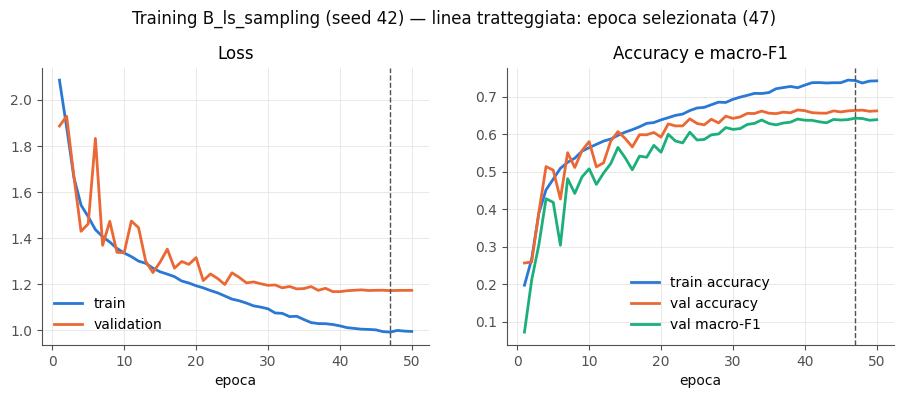

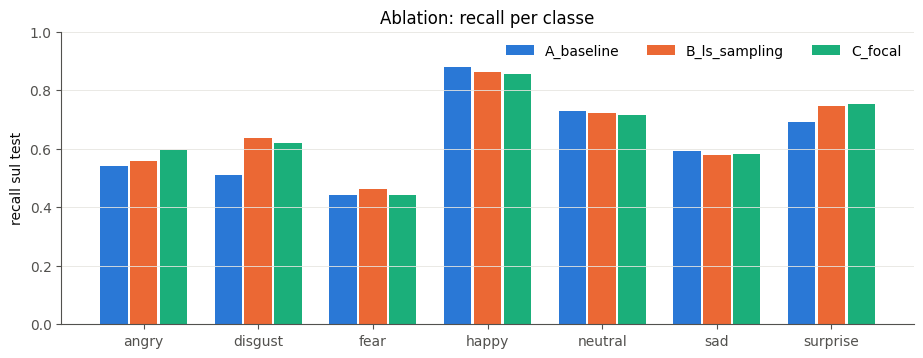

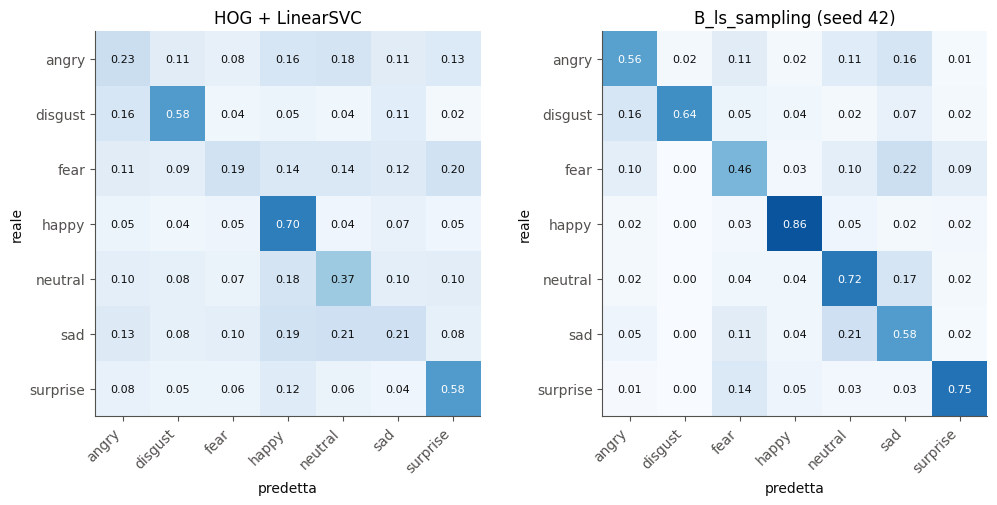

In [14]:
import matplotlib.pyplot as plt

SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']  # fixed categorical order
TEXT, MUTED = '#0b0b0b', '#52514e'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': MUTED,
                     'axes.labelcolor': TEXT, 'xtick.color': MUTED, 'ytick.color': MUTED,
                     'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.6, 'font.size': 10})

def savefig(fig, name):
    fig.savefig(os.path.join(FIG_DIR, name), dpi=200, bbox_inches='tight')
    plt.show()

# Training curves of the final model
hist = json.load(open(os.path.join(RUN_DIR, f'{BEST}_s{SEED}', 'history.json')))
ep = np.arange(1, len(hist['loss']) + 1)
best_ep = RESULTS[(BEST, SEED)]['best_epoch']
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(ep, hist['loss'], color=SERIES[0], lw=2, label='train')
axes[0].plot(ep, hist['val_loss'], color=SERIES[1], lw=2, label='validation')
axes[0].set(title='Loss', xlabel='epoca')
axes[1].plot(ep, hist['accuracy'], color=SERIES[0], lw=2, label='train accuracy')
axes[1].plot(ep, hist['val_accuracy'], color=SERIES[1], lw=2, label='val accuracy')
axes[1].plot(ep, hist['val_macro_f1'], color=SERIES[2], lw=2, label='val macro-F1')
axes[1].set(title='Accuracy e macro-F1', xlabel='epoca')
for ax in axes:
    ax.axvline(best_ep, color=MUTED, ls='--', lw=1)
    ax.legend(frameon=False)
fig.suptitle(f'Training {BEST} (seed {SEED}) — linea tratteggiata: epoca selezionata ({best_ep})', color=TEXT, y=1.04)
savefig(fig, 'training_curves.png')

# Ablation: per-class recall on the test set
abl = list(EXPERIMENTS)
fig, ax = plt.subplots(figsize=(11, 3.8))
w = 0.26
for i, name in enumerate(abl):
    ax.bar(np.arange(N_CLASSES) + (i - 1) * w, PER_CLASS[name], w - 0.02, color=SERIES[i], label=name)
ax.set_xticks(np.arange(N_CLASSES), CLASSES)
ax.set(ylabel='recall sul test', ylim=(0, 1), title='Ablation: recall per classe')
ax.legend(frameon=False, ncol=3)
ax.grid(axis='x', visible=False)
savefig(fig, 'ablation_recall.png')

# Normalized confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (title, pred) in zip(axes, [('HOG + LinearSVC', svm_test_pred), (f'{BEST} (seed {SEED})', FINAL)]):
    cm = confusion_matrix(y_te, pred, normalize='true')
    ax.imshow(cm, cmap='Blues', vmin=0, vmax=1)
    for i in range(N_CLASSES):
        for j in range(N_CLASSES):
            ax.text(j, i, f'{cm[i, j]:.2f}', ha='center', va='center', fontsize=8,
                    color='white' if cm[i, j] > 0.5 else TEXT)
    ax.set_xticks(range(N_CLASSES), CLASSES, rotation=45, ha='right')
    ax.set_yticks(range(N_CLASSES), CLASSES)
    ax.set(title=title, xlabel='predetta', ylabel='reale')
    ax.grid(False)
savefig(fig, 'confusion_matrices.png')

## 9. Failure modes
Coppie di classi più confuse dal modello finale, esempi degli errori commessi con maggiore confidenza e mappe Grad-CAM (regioni del volto che più influenzano la predizione).

Coppie più confuse (reale → predetta):
       fear → sad        21.6% (114 immagini)
        sad → neutral    20.5% (122 immagini)
    neutral → sad        16.8% (105 immagini)
      angry → sad        16.5% (81 immagini)
    disgust → angry      16.4% (9 immagini)
   surprise → fear       13.7% (57 immagini)


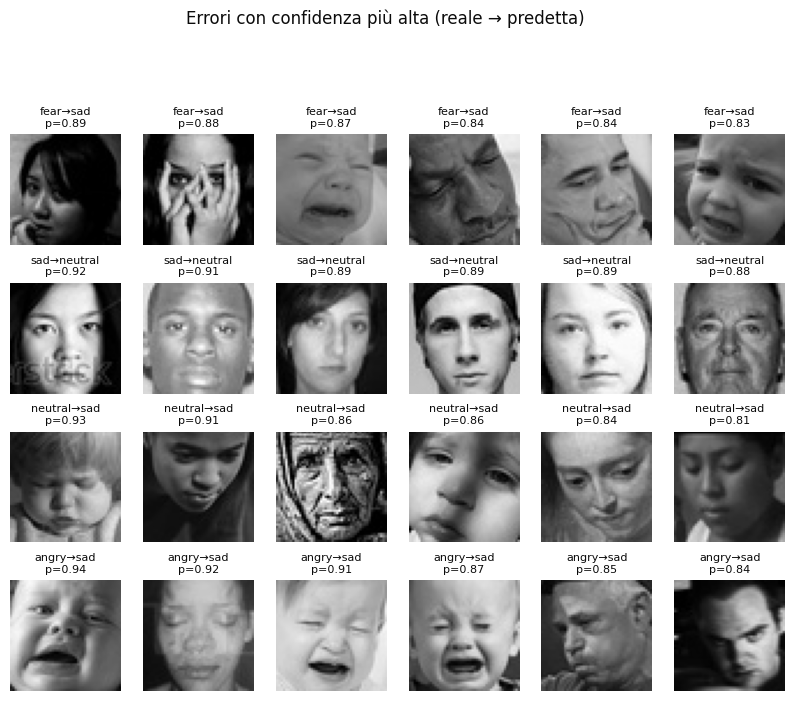

In [15]:
cm_counts = confusion_matrix(y_te, FINAL)
cm_norm = cm_counts / cm_counts.sum(1, keepdims=True)
pairs = sorted(((cm_norm[i, j], i, j) for i in range(N_CLASSES) for j in range(N_CLASSES) if i != j), reverse=True)[:6]
CONFUSIONS = [{'true': CLASSES[i], 'pred': CLASSES[j], 'rate': float(r), 'count': int(cm_counts[i, j])} for r, i, j in pairs]
print('Coppie più confuse (reale → predetta):')
for c in CONFUSIONS:
    print(f"  {c['true']:>9} → {c['pred']:<9} {100 * c['rate']:5.1f}% ({c['count']} immagini)")

proba = TEST_PROBA[(BEST, SEED)]
fig, axes = plt.subplots(4, 6, figsize=(10, 7.4))
for row, (_, i, j) in zip(axes, pairs[:4]):
    idx = np.where((y_te == i) & (FINAL == j))[0]
    idx = idx[np.argsort(-proba[idx, j])][:6]
    for ax in row:
        ax.axis('off')
    for ax, k in zip(row, idx):
        ax.imshow(X_te[k], cmap='gray', vmin=0, vmax=255)
        ax.set_title(f'{CLASSES[i]}→{CLASSES[j]}\np={proba[k, j]:.2f}', fontsize=8, color=TEXT)
fig.suptitle('Errori con confidenza più alta (reale → predetta)', color=TEXT, y=1.04)
savefig(fig, 'failure_examples.png')

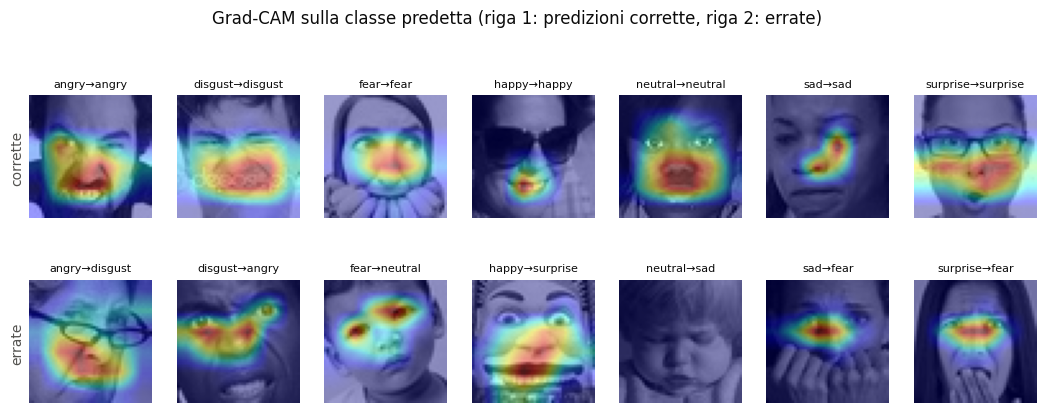

In [16]:
final_model = MODELS[(BEST, SEED)]
grad_model = tf.keras.Model(final_model.input, [final_model.get_layer('last_conv').output, final_model.output])

def grad_cam(x, cls):
    with tf.GradientTape() as tape:
        conv, pred = grad_model(x[None, ..., None].astype('float32'), training=False)
        score = pred[0, cls]
    # gradient w.r.t. the layer output itself (a cast copy would not be on the tape)
    grads = tf.cast(tape.gradient(score, conv), tf.float32)
    conv = tf.cast(conv, tf.float32)
    cam = tf.nn.relu(tf.reduce_sum(conv[0] * tf.reduce_mean(grads, axis=(0, 1, 2)), axis=-1))
    cam = tf.image.resize(cam[..., None], (IMG_SIZE, IMG_SIZE))[..., 0].numpy()
    return cam / (cam.max() + 1e-8)

fig, axes = plt.subplots(2, N_CLASSES, figsize=(13, 4.4))
for k in range(N_CLASSES):
    for row, correct in enumerate([True, False]):
        ax = axes[row, k]
        ax.axis('off')
        mask = (y_te == k) & ((FINAL == k) if correct else (FINAL != k))
        idx = np.where(mask)[0]
        if len(idx) == 0:
            continue
        n = idx[np.argmax(proba[idx, FINAL[idx]])]
        ax.imshow(X_te[n], cmap='gray', vmin=0, vmax=255)
        ax.imshow(grad_cam(X_te[n], FINAL[n]), cmap='jet', alpha=0.4)
        ax.set_title(f'{CLASSES[k]}→{CLASSES[FINAL[n]]}', fontsize=8, color=TEXT)
axes[0, 0].text(-8, 24, 'corrette', rotation=90, va='center', color=MUTED)
axes[1, 0].text(-8, 24, 'errate', rotation=90, va='center', color=MUTED)
fig.suptitle('Grad-CAM sulla classe predetta (riga 1: predizioni corrette, riga 2: errate)', color=TEXT, y=1.04)
savefig(fig, 'gradcam.png')

## 10. Analisi dei bias sui sottogruppi
**Limite dichiarato:** FER-2013 non contiene attributi demografici (genere, età, etnia), quindi un'analisi demografica diretta non è possibile senza annotazioni aggiuntive; stimarli con un altro modello su volti 48×48 introdurrebbe un secondo errore non controllabile. L'analisi si concentra quindi sui **bias di acquisizione** misurabili dai pixel:
- **luminosità** (media dei pixel), **contrasto** (deviazione standard), **nitidezza** (varianza del Laplaciano);
- ogni fattore divide il test in quartili; per ciascuno si riportano accuracy (IC bootstrap 95%) e *balanced accuracy* (media delle recall per classe), che non dipende dalla diversa composizione di classi tra quartili;
- il test del chi-quadro verifica se correttezza e quartile sono indipendenti. Un p-value alto indica *assenza di evidenza* di un bias, non la sua assenza dimostrata.

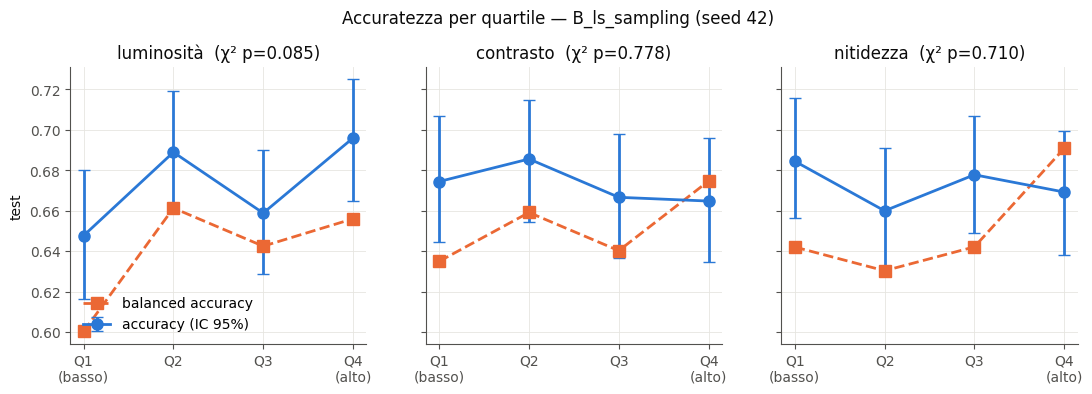

luminosità  acc Q1..Q4 = [0.6477, 0.689, 0.6589, 0.696]  balanced = [0.6003, 0.6614, 0.6425, 0.656]  χ² p = 0.0852  (composizione classi vs quartile: p = 3.89e-32)
            acc per seed: [[0.6477, 0.689, 0.6589, 0.696], [0.6522, 0.6912, 0.6633, 0.6938], [0.6511, 0.6745, 0.6667, 0.6938]]
contrasto   acc Q1..Q4 = [0.6745, 0.6856, 0.6667, 0.6648]  balanced = [0.635, 0.6592, 0.6403, 0.6747]  χ² p = 0.7784  (composizione classi vs quartile: p = 6.90e-02)
            acc per seed: [[0.6745, 0.6856, 0.6667, 0.6648], [0.6845, 0.6778, 0.6644, 0.6737], [0.6834, 0.6734, 0.6633, 0.6659]]
nitidezza   acc Q1..Q4 = [0.6845, 0.66, 0.6778, 0.6693]  balanced = [0.6421, 0.6303, 0.6421, 0.6909]  χ² p = 0.7099  (composizione classi vs quartile: p = 6.67e-15)
            acc per seed: [[0.6845, 0.66, 0.6778, 0.6693], [0.6901, 0.6589, 0.6845, 0.667], [0.68, 0.6722, 0.6689, 0.6648]]

Recall per classe: quartile più scuro (Q1) vs più chiaro (Q4)
  angry     Q1=0.447  Q4=0.566  (n=114/113)
  disgust   Q1=0.6

In [17]:
from scipy.ndimage import laplace
from scipy.stats import chi2_contingency
from sklearn.metrics import balanced_accuracy_score

FACTORS = {
    'luminosità': X_te.mean(axis=(1, 2)),
    'contrasto': X_te.std(axis=(1, 2)),
    'nitidezza': np.array([laplace(x.astype(np.float32)).var() for x in X_te]),
}
BIAS = {}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, (fname, v) in zip(axes, FACTORS.items()):
    q = np.digitize(v, np.quantile(v, [0.25, 0.5, 0.75]))
    correct = FINAL == y_te
    table = [[int((correct & (q == b)).sum()), int((~correct & (q == b)).sum())] for b in range(4)]
    chi2, p, _, _ = chi2_contingency(table)
    mix = np.array([[((q == b) & (y_te == k)).sum() for k in range(N_CLASSES)] for b in range(4)])
    _, p_classes, _, _ = chi2_contingency(mix[:, mix.sum(0) > 0])
    acc = [accuracy_score(y_te[q == b], FINAL[q == b]) for b in range(4)]
    ci = [bootstrap_ci(y_te[q == b], FINAL[q == b], accuracy_score) for b in range(4)]
    bal = [balanced_accuracy_score(y_te[q == b], FINAL[q == b]) for b in range(4)]
    seeds_acc = [[accuracy_score(y_te[q == b], TEST_PRED[(BEST, s)][q == b]) for b in range(4)] for s in SEEDS]
    BIAS[fname] = {'quartile_edges': np.quantile(v, [0.25, 0.5, 0.75]).tolist(), 'acc': acc, 'acc_ci': ci,
                   'balanced_acc': bal, 'acc_per_seed': seeds_acc, 'chi2': float(chi2), 'p_value': float(p),
                   'p_value_class_mix_vs_quartile': float(p_classes)}
    x = np.arange(4)
    ax.errorbar(x, acc, yerr=[np.array(acc) - [c[0] for c in ci], [c[1] for c in ci] - np.array(acc)],
                fmt='o-', color=SERIES[0], lw=2, ms=8, capsize=4, label='accuracy (IC 95%)')
    ax.plot(x, bal, 's--', color=SERIES[1], lw=2, ms=8, label='balanced accuracy')
    ax.set_xticks(x, ['Q1\n(basso)', 'Q2', 'Q3', 'Q4\n(alto)'])
    ax.set_title(f'{fname}  (χ² p={p:.3f})', color=TEXT)
axes[0].set_ylabel('test')
axes[0].legend(frameon=False, loc='lower left')
fig.suptitle(f'Accuratezza per quartile — {BEST} (seed {SEED})', color=TEXT, y=1.04)
savefig(fig, 'bias_subgroups.png')

for fname, b in BIAS.items():
    print(f"{fname:<11} acc Q1..Q4 = {np.round(b['acc'], 4).tolist()}  balanced = {np.round(b['balanced_acc'], 4).tolist()}  "
          f"χ² p = {b['p_value']:.4f}  (composizione classi vs quartile: p = {b['p_value_class_mix_vs_quartile']:.2e})")
    print(f"{'':<11} acc per seed: {np.round(b['acc_per_seed'], 4).tolist()}")

q_b = np.digitize(FACTORS['luminosità'], np.quantile(FACTORS['luminosità'], [0.25, 0.5, 0.75]))
print('\nRecall per classe: quartile più scuro (Q1) vs più chiaro (Q4)')
for k, c in enumerate(CLASSES):
    r = [recall_score(y_te[q_b == b] == k, FINAL[q_b == b] == k, zero_division=0) for b in (0, 3)]
    print(f'  {c:<9} Q1={r[0]:.3f}  Q4={r[1]:.3f}  (n={int(((q_b == 0) & (y_te == k)).sum())}/{int(((q_b == 3) & (y_te == k)).sum())})')

## 11. Esportazione dei risultati

In [18]:
ALL_RESULTS = {
    'environment': ENV, 'data_audit': AUDIT, 'hog_svm': SVM_RES,
    'validation': {f'{k[0]}_s{k[1]}': v for k, v in RESULTS.items()},
    'selected_config': BEST, 'test': TEST_RESULTS, 'test_seed_summary': SEED_SUMMARY,
    'test_recall_per_class': {k: dict(zip(CLASSES, v)) for k, v in PER_CLASS.items()},
    'mcnemar': MCNEMAR, 'top_confusions': CONFUSIONS, 'bias': BIAS,
}
with open(os.path.join(OUT_DIR, 'results.json'), 'w') as f:
    json.dump(ALL_RESULTS, f, indent=2, default=float)
print('Salvati:', sorted(os.listdir(OUT_DIR)), sorted(os.listdir(FIG_DIR)))

Salvati: ['data_audit.json', 'environment.json', 'figures', 'results.json', 'runs'] ['ablation_recall.png', 'bias_subgroups.png', 'confusion_matrices.png', 'failure_examples.png', 'gradcam.png', 'training_curves.png']


## 12. Sintesi
- **CNN vs HOG + SVM.** La ResNet-Lite supera la pipeline classica di circa 27 punti di accuracy (McNemar, p < 10⁻¹⁵⁰). La SVM ottiene una recall di *Disgust* relativamente alta solo perché lo predice molto spesso (precisione 0.11).
- **Mitigazioni.** Label smoothing e balanced sampling non cambiano in modo significativo l'accuracy (B vs A, p = 0.35), ma aumentano la macro-F1 (0.636 → 0.656) e la recall delle classi rare: ridistribuiscono gli errori tra le classi. Con 55 esempi di test, il guadagno su *Disgust* ha un'incertezza ampia.
- **Transfer learning.** MobileNetV2 (63.2%) è significativamente peggiore della rete addestrata da zero: le feature di ImageNet si adattano male a volti 48×48 in scala di grigi.
- **Failure modes.** Le confusioni principali sono *Fear → Sad*, *Sad ↔ Neutral*, *Angry → Sad* e *Surprise → Fear*. Diversi errori con confidenza alta riguardano immagini con etichette ambigue o errate, coerentemente con il rumore noto di FER-2013.
- **Bias.** Contrasto e nitidezza non influiscono sull'accuratezza. Le immagini più scure hanno l'accuratezza più bassa, ma la differenza non è significativa (p = 0.085) ed è in parte spiegata dalla diversa composizione delle classi. FER-2013 non contiene attributi demografici: un'analisi di equità per genere, età o etnia richiederebbe un dataset annotato.